In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib
import matplotlib.pyplot as plt
import palantir as pl
import anndata as ad
from matplotlib.backends.backend_pdf import PdfPages
# import pyreadr as pr
import re
import os
matplotlib.rcParams['font.family'] = ['serif']

In [2]:
def plot_gene_expr(expr, vis, dim1, dim2, genes, file, n_cols, s=3, 
                   newGeneName=None):
    cmap = matplotlib.cm.Spectral_r
    fig = pl.plot.FigureGrid(len(genes), n_cols)
    for g, ax in zip(genes, fig):
        c = expr.loc[vis.index, g]
        ax.scatter(vis.loc[:, dim1], vis.loc[:, dim2], s=s, c=c, cmap=cmap)
        ax.set_axis_off()
        if newGeneName and g in newGeneName:
            figTitle = newGeneName[g]
        else:
            figTitle = g
        ax.set_title(figTitle)
        normalize = matplotlib.colors.Normalize(vmin=np.min(c), vmax=np.max(c))
        cax, _ = matplotlib.colorbar.make_axes(ax)
        cb = matplotlib.colorbar.ColorbarBase(cax, norm=normalize, cmap=cmap)
        #cb.ax.set_title('Expression')
        cb.set_label('Expression')
    n_rows = math.ceil(len(genes) / n_cols)
    fig.figure.set_size_inches(7 * n_cols, 5 * n_rows)
    file.savefig(fig.figure, bbox_inches='tight')
    return 0

def plot_gene_expr_grayout(expr, vis, vis2, dim1, dim2, genes, file, n_cols, figTitle, s=3, 
                   newGeneName=None):
    cmap = matplotlib.cm.Spectral_r
    fig = pl.plot.FigureGrid(len(genes), n_cols)
    for g, ax in zip(genes, fig):
        c = expr.loc[vis.index, g]
        ax.scatter(vis2.loc[:, dim1], vis2.loc[:, dim2], s=s, c='gray')
        ax.scatter(vis.loc[:, dim1], vis.loc[:, dim2], s=s, c=c, cmap=cmap)
        ax.set_axis_off()
        if newGeneName and g in newGeneName:
            figTitle = newGeneName[g]
        else:
            figTitle = g
        ax.set_title(figTitle)
        normalize = matplotlib.colors.Normalize(vmin=np.min(c), vmax=np.max(c))
        cax, _ = matplotlib.colorbar.make_axes(ax)
        matplotlib.colorbar.ColorbarBase(cax, norm=normalize, cmap=cmap)
    n_rows = math.ceil(len(genes) / n_cols)
    fig.figure.set_size_inches(7 * n_cols, 5 * n_rows)
    file.savefig(fig.figure, bbox_inches='tight')
    return 0

# load data

In [3]:
adata = ad.read_h5ad("Seurat/unimputed-expr.h5ad")
unimp_df = pd.DataFrame(adata.X.toarray(), index=adata.obs_names, columns = adata.var_names)


pref_p = "plots/gene-expr"
os.makedirs(pref_p, exist_ok = True)

In [4]:
md = pd.read_csv('Seurat/meta-data.csv', header=0, index_col=0)

In [5]:
umap = pd.read_csv('Seurat/UMAP.csv', header=0, index_col=0)
# idx = [str(c) for c in list(umap.index)]
# umap.index = idx

In [6]:
genes = unimp_df.columns

# Genes

In [15]:
geneList = [
    "Rorc",
    "Il22",
    "Zbtb16",
    "Rora",
    "Tcf7",
    "Ets1",
    "Cxcr6",
    "Il7r",
    "Il23r",
    "Lta",
    "Tbx21",
    "Stat1",
    "Igtp",
    "Ildr1",
    "Gimap4",
    "Cxcr3",
    "Irf8",
    "Prdm16",
    "Spi1",
    "Sirpa",
    "Pld4",
    "Ccr6",
    "Flt3",
    "Itgax",
    "Itgam",
    "H2-DMa",
    "H2-Eb1",
    "H2-Aa",
]
[g for g in geneList if g not in genes]

[]

In [16]:
# unimputed
ci = md.index
title = "panel_c"
ncols = 3

In [ ]:
file = PdfPages(os.path.join(pref_p, 'UMAP-unimputed-' + title + '.pdf'))
plot_gene_expr(expr=unimp_df.loc[ci, :], vis=umap.loc[ci, :], dim1='UMAP_1', dim2='UMAP_2', genes=geneList,
               file=file, n_cols=ncols)
file.close()

In [18]:
geneList = ['Rorc', 'Il1r2', 'Itgam', 'Sirpa'
]
[g for g in geneList if g not in genes]

[]

In [19]:
# unimputed
ci = md.index
title = "FL_TLP_signatures"
ncols = 3

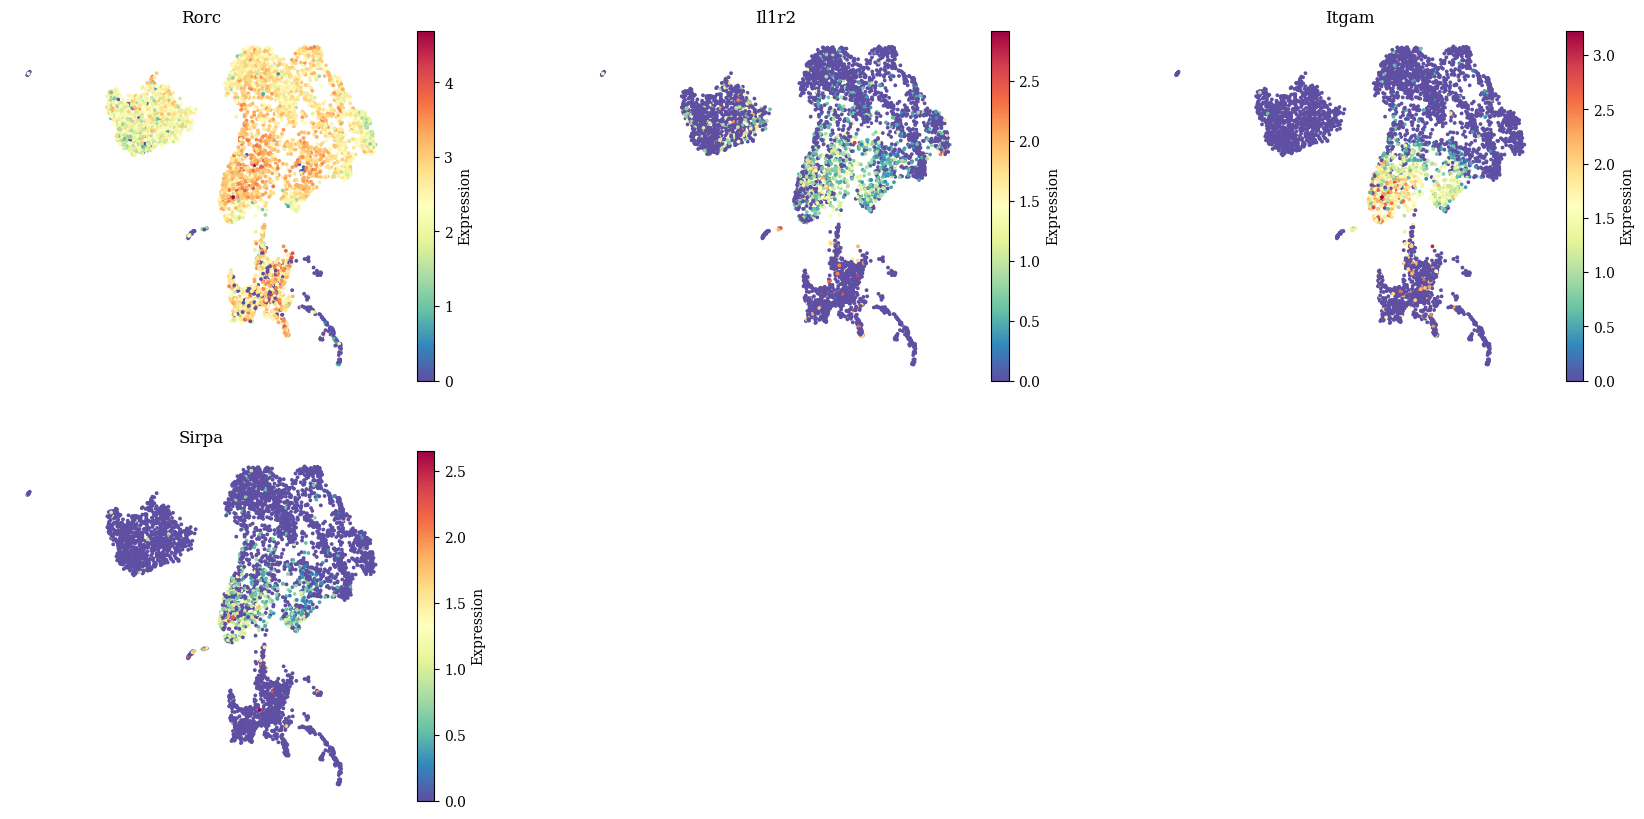

In [20]:
file = PdfPages(os.path.join(pref_p, 'UMAP-unimputed-' + title + '.pdf'))
plot_gene_expr(expr=unimp_df.loc[ci, :], vis=umap.loc[ci, :], dim1='UMAP_1', dim2='UMAP_2', genes=geneList,
               file=file, n_cols=ncols)
file.close()

# subset

In [4]:
adata = ad.read_h5ad("Seurat/res1_ex_c1c5c13c14c15/unimputed-expr.h5ad")
unimp_df = pd.DataFrame(adata.X.toarray(), index=adata.obs_names, columns = adata.var_names)


pref_p = "plots/res1_ex_c1c5c13c14c15/gene-expr"
os.makedirs(pref_p, exist_ok = True)

In [6]:
md = pd.read_csv('Seurat/res1_ex_c1c5c13c14c15/meta-data.csv', header=0, index_col=0)
umap = pd.read_csv('Seurat/res1_ex_c1c5c13c14c15/UMAP.csv', header=0, index_col=0)

In [7]:
genes = unimp_df.columns

# Genes

In [8]:
geneList = [
    "Rorc",
    "Il22",
    "Zbtb16",
    "Rora",
    "Tcf7",
    "Ets1",
    "Cxcr6",
    "Il7r",
    "Il23r",
    "Lta",
    "Tbx21",
    "Stat1",
    "Igtp",
    "Ildr1",
    "Gimap4",
    "Cxcr3",
    "Irf8",
    "Prdm16",
    "Spi1",
    "Sirpa",
    "Pld4",
    "Ccr6",
    "Flt3",
    "Itgax",
    "Itgam",
    "H2-DMa",
    "H2-Eb1",
    "H2-Aa",
]
[g for g in geneList if g not in genes]

[]

In [9]:
# unimputed
ci = md.index
title = "panel_c"
ncols = 3

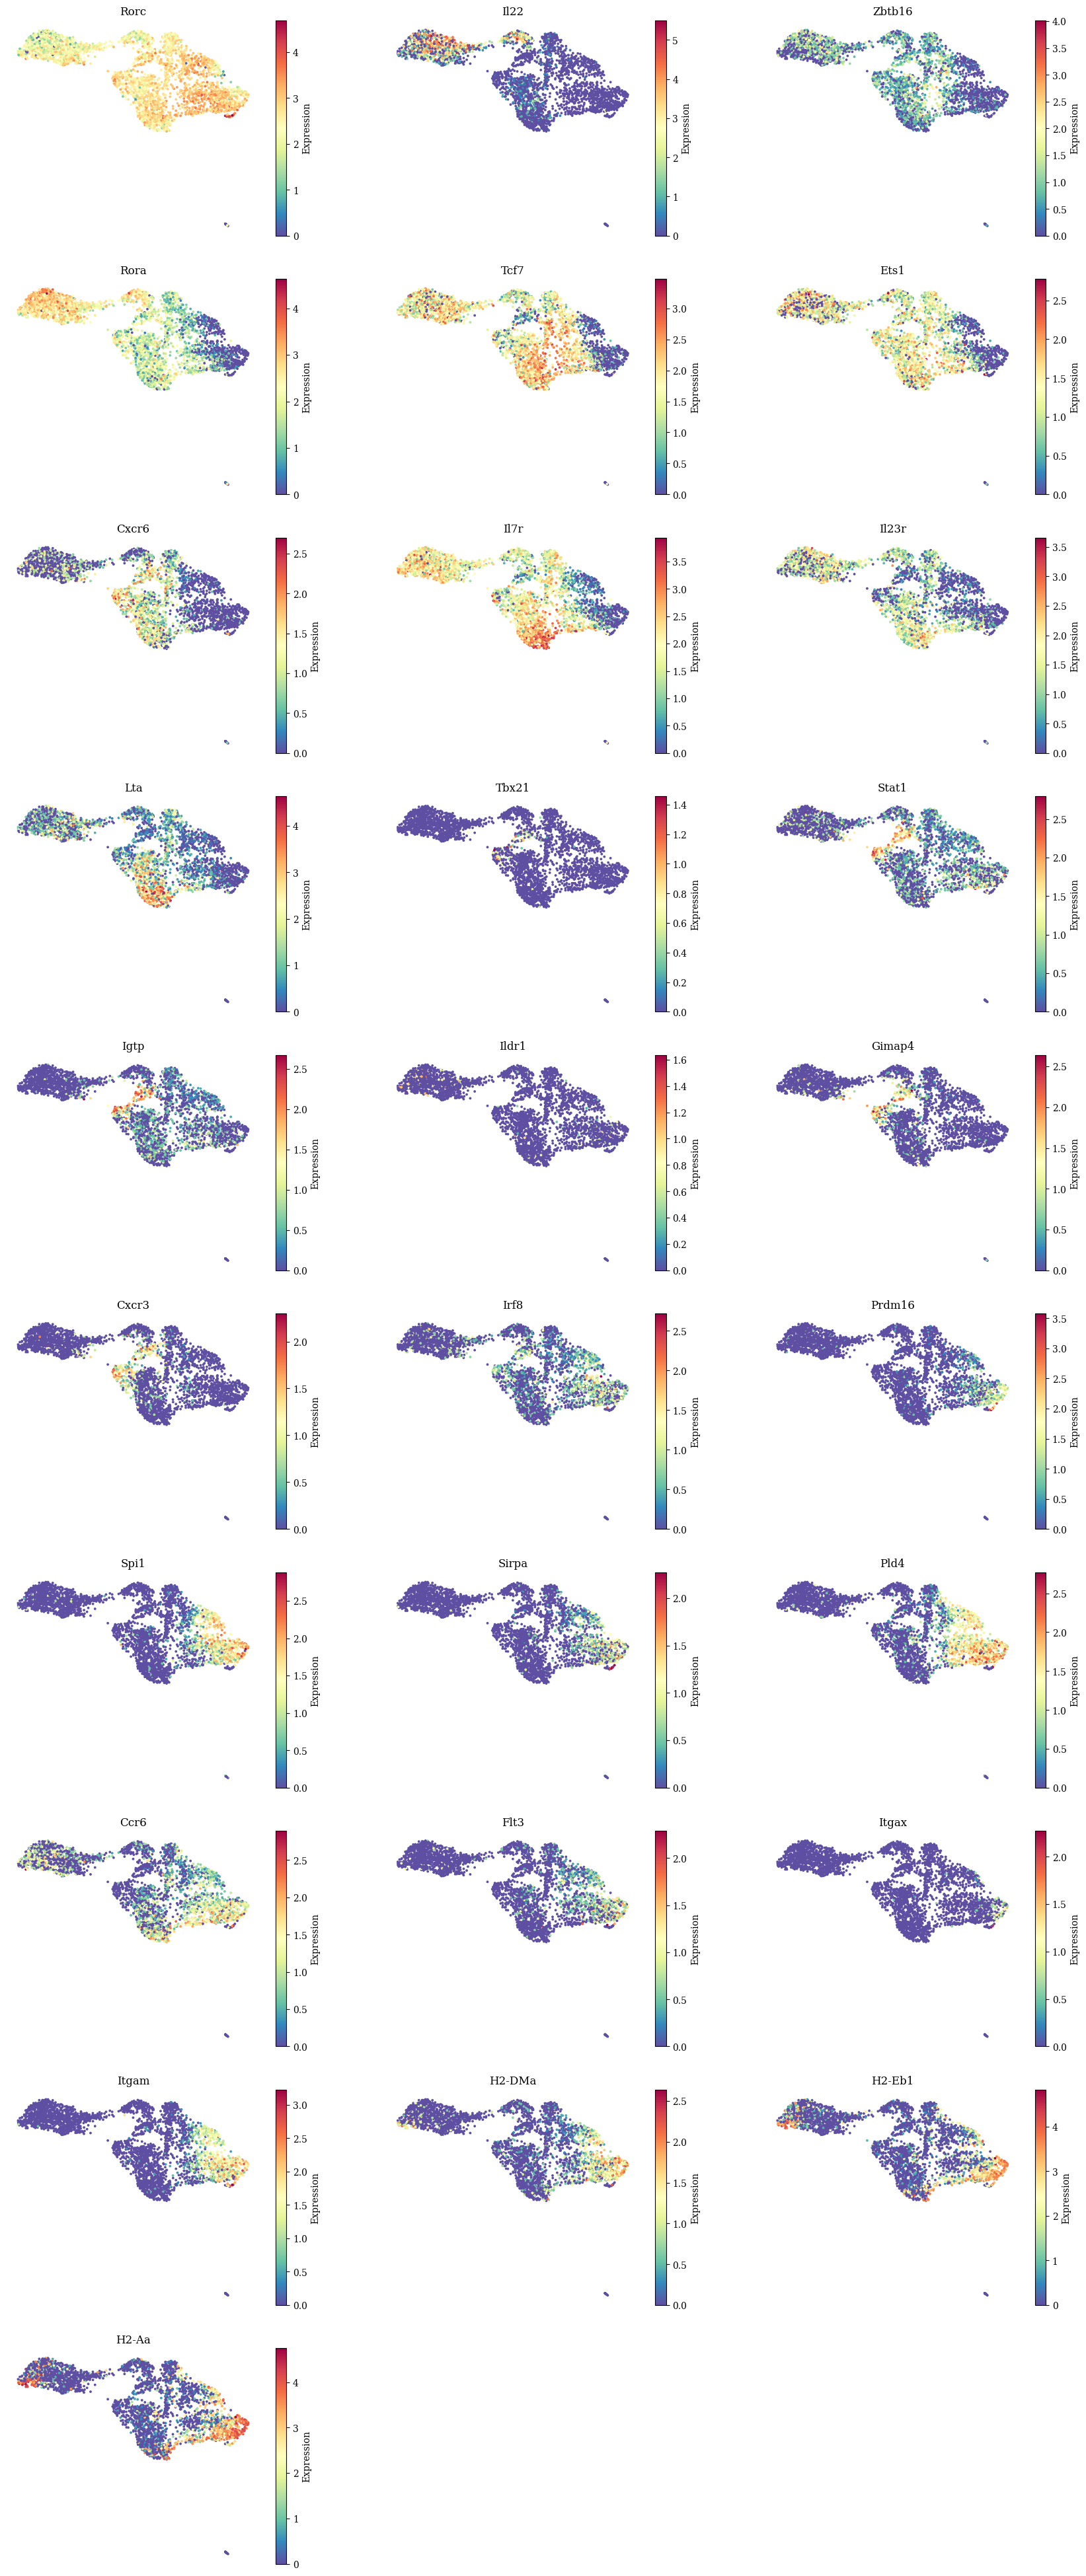

In [10]:
file = PdfPages(os.path.join(pref_p, 'UMAP-unimputed-' + title + '.pdf'))
plot_gene_expr(expr=unimp_df.loc[ci, :], vis=umap.loc[ci, :], dim1='UMAP_1', dim2='UMAP_2', genes=geneList,
               file=file, n_cols=ncols)
file.close()

In [11]:
geneList = ['Rorc', 'Il1r2', 'Itgam', 'Sirpa'
]
[g for g in geneList if g not in genes]

[]

In [12]:
# unimputed
ci = md.index
title = "FL_TLP_signatures"
ncols = 3

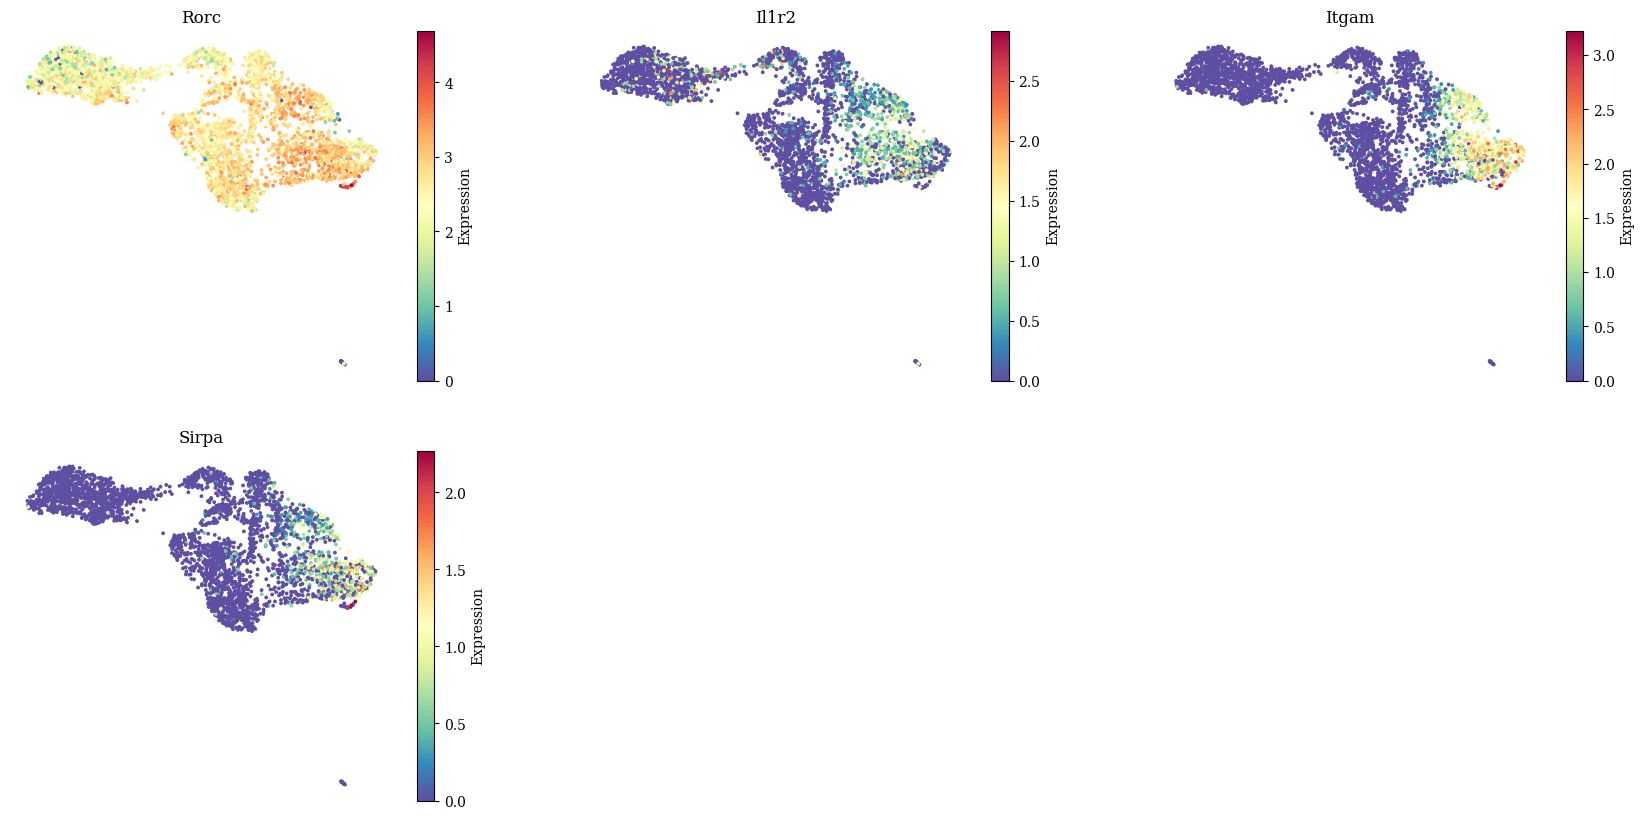

In [13]:
file = PdfPages(os.path.join(pref_p, 'UMAP-unimputed-' + title + '.pdf'))
plot_gene_expr(expr=unimp_df.loc[ci, :], vis=umap.loc[ci, :], dim1='UMAP_1', dim2='UMAP_2', genes=geneList,
               file=file, n_cols=ncols)
file.close()